# Tome S2, Chapter 8: Cubic curves (Python companion)

Exercises first, solutions at the end. We implement the chord-and-tangent law exactly, follow Bachet's point until its coordinates explode, test associativity on every triple of points of small curves over $\mathbb F_p$, find the nine flexes and their twelve lines, count points to see Hasse's bound, and break a toy discrete logarithm. We use `fractions`, `numpy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math, random
from fractions import Fraction as Fr
import numpy as np
import matplotlib.pyplot as plt
random.seed(8)

## Exercises

**P8.1 (★) Bachet's point.** Implement the addition formulas of Section 8.2 over $\mathbb Q$ and compute $nP$ for $P=(3,5)$ on $y^2=x^3-2$, $n\le 12$. Check Exercise 8.3, and plot the number of digits of the denominator of $x(nP)$ against $n$. What shape do you see?

**P8.2 (★) Associativity by brute force.** Implement the group law over $\mathbb F_p$ and check $(P+Q)+R=P+(Q+R)$ for *every* triple of points of a few curves with $p\le 23$, including the degenerate triples left out of Theorem 8.4.

**P8.3 (★★) Nine flexes, twelve lines.** For a random curve $y^2=x^3+ax+b$ over $\mathbb C$, compute the nine flexes from $\psi$ (Theorem 8.6), check that $3P=O$ for each, and find all collinear triples among them. How many are real (Theorem 8.7)?

**P8.4 (★★) Hasse's bound and its fine print.** For $y^2=x^3-x+1$ and all primes $p<3000$, compute $a_p=p+1-\#E(\mathbb F_p)$ with Proposition 8.8, check $|a_p|\le2\sqrt p$, and draw the histogram of $a_p/(2\sqrt p)$. Do the same for $y^2=x^3-x$ and explain the spike with Proposition 8.9.

**P8.5 (★★) A toy discrete logarithm.** On $E:y^2=x^3+2x+3$ over $\mathbb F_{p}$ with $p=10007$, take a point $P$, a secret $n$, and $Q=nP$. Recover $n$ from $P$ and $Q$ with the baby-step giant-step method, in about $\sqrt{\#E}$ steps. Why does nobody know how to do much better on well-chosen curves?

## Solutions

### P8.1
**How to find it.** Represent $O$ by `None`. The tangent case has slope $\frac{3x^2+a}{2y}$; if $y=0$ the tangent is vertical and $2P=O$.

1 3 5 True
2 129/100 -383/1000 True
3 164323/29241 -66234835/5000211 True
4 2340922881/58675600 113259286337279/449455096000 True
digits of the denominators: [1, 3, 5, 8, 15, 21, 28, 37, 48, 59, 69, 84]
fitted constant c = 0.581


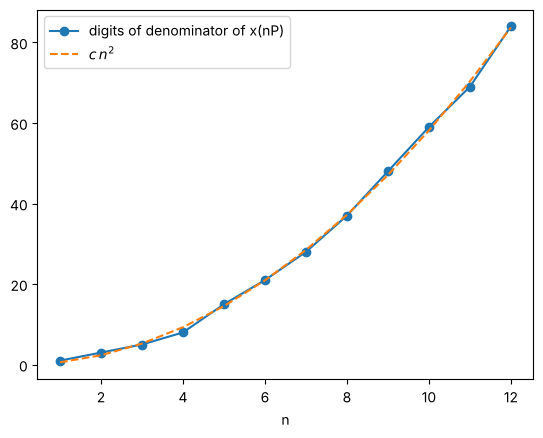

In [2]:
def ec_add(P, Q, a, inv=lambda u: 1 / u, mod=lambda u: u):
    if P is None: return Q
    if Q is None: return P
    (x1, y1), (x2, y2) = P, Q
    if mod(x1 - x2) == 0 and mod(y1 + y2) == 0: return None
    lam = mod((y2 - y1) * inv(x2 - x1)) if mod(x1 - x2) != 0 else mod((3 * x1 * x1 + a) * inv(2 * y1))
    x3 = mod(lam * lam - x1 - x2)
    return (x3, mod(-(y1 + lam * (x3 - x1))))

def mult(n, P, add):
    R, Q = None, P
    while n:
        if n & 1: R = add(R, Q)
        Q, n = add(Q, Q), n >> 1
    return R

add_Q = lambda P, Q: ec_add(P, Q, 0)
P = (Fr(3), Fr(5)); pts = [P]
for n in range(2, 13): pts.append(add_Q(pts[-1], P))
for n, (x, y) in enumerate(pts[:4], 1): print(n, x, y, y * y == x**3 - 2)
digits = [len(str(x.denominator)) for x, y in pts]
print('digits of the denominators:', digits)
n = np.arange(1, 13)
c = np.dot(digits, n**2) / np.dot(n**2, n**2)            # least-squares fit digits ~ c n^2
print('fitted constant c = %.3f' % c)
plt.plot(n, digits, 'o-', label='digits of denominator of x(nP)'); plt.plot(n, c * n**2, '--', label='$c\\,n^2$')
plt.xlabel('n'); plt.legend(); plt.show()

The third line is Exercise 8.3. The number of digits grows like $n^2$: this quadratic growth of the *height* is the engine of the proof of Mordell's theorem in Tome 12. (The constant $c$, about $0.58$, is a least-squares fit.)

### P8.2
**How to find it.** Same formulas, with arithmetic mod $p$ and the inverse `pow(u, -1, p)`.

In [3]:
def curve_points(p, a, b):
    sq = {}
    for y in range(p): sq.setdefault(y * y % p, []).append(y)
    return [None] + [(x, y) for x in range(p) for y in sq.get((x**3 + a * x + b) % p, [])]

def adder(p, a):
    return lambda P, Q: ec_add(P, Q, a, inv=lambda u: pow(u % p, -1, p), mod=lambda u: u % p)

for p, a, b in [(5, 1, 1), (7, 3, 2), (11, 1, 6), (13, 2, 5), (23, 1, 1)]:
    if (4 * a**3 + 27 * b**2) % p == 0: continue
    E = curve_points(p, a, b); add = adder(p, a)
    bad = sum(add(add(P, Q), R) != add(P, add(Q, R)) for P in E for Q in E for R in E)
    print('p=%2d  y^2=x^3+%dx+%d  #E=%3d  triples tested=%7d  failures=%d' % (p, a, b, len(E), len(E)**3, bad))

p= 5  y^2=x^3+1x+1  #E=  9  triples tested=    729  failures=0
p= 7  y^2=x^3+3x+2  #E=  9  triples tested=    729  failures=0
p=11  y^2=x^3+1x+6  #E= 13  triples tested=   2197  failures=0
p=13  y^2=x^3+2x+5  #E= 12  triples tested=   1728  failures=0
p=23  y^2=x^3+1x+1  #E= 28  triples tested=  21952  failures=0


No failures, degenerate triples included: the remark after Theorem 8.4 in action.

### P8.3
**How to find it.** The roots of $\psi(x)=3x^4+6ax^2+12bx-a^2$ give the abscissas; each gives $y=\pm\sqrt{f(x)}$. Three affine points are collinear when the $3\times3$ determinant of their homogeneous coordinates vanishes; a triple containing $O$ is collinear when the two affine points are vertically aligned.

In [4]:
a, b = -1.0, 1.0                                       # the curve of the figure
xs = np.roots([3, 0, 6 * a, 12 * b, -a * a])
flex = [None] + [(x, s * np.sqrt(complex(x**3 + a * x + b))) for x in xs for s in (1, -1)]
cadd = lambda P, Q: ec_add(P, Q, a)
def close(P, Q): return (P is None and Q is None) or (P is not None and Q is not None and abs(P[0] - Q[0]) + abs(P[1] - Q[1]) < 1e-6)
def triple(P):
    T = cadd(cadd(P, P), P) if P is not None else None
    return T is None or abs(T[0]) > 1e8                 # 3P = O, up to rounding
print('3P = O for all nine:', all(triple(P) for P in flex))
def collinear(P, Q, R):
    if None in (P, Q, R):
        U, V = [S for S in (P, Q, R) if S is not None]
        return abs(U[0] - V[0]) < 1e-8
    M = np.array([[P[0], P[1], 1], [Q[0], Q[1], 1], [R[0], R[1], 1]])
    return abs(np.linalg.det(M)) < 1e-8
lines = [T for T in itertools.combinations(range(9), 3) if collinear(*(flex[i] for i in T))]
print(len(lines), 'collinear triples; each flex lies on', {sum(i in T for T in lines) for i in range(9)}, 'of them')
real = [P for P in flex if P is None or (abs(P[0].imag) < 1e-9 and abs(P[1].imag) < 1e-9)]
print('real flexes:', real)

3P = O for all nine: True
12 collinear triples; each flex lies on {4} of them
real flexes: [None, (np.complex128(0.08711329962483431+0j), np.complex128(0.9557969341976398+0j)), (np.complex128(0.08711329962483431+0j), np.complex128(-0.9557969341976398+0j))]


Twelve lines, four through each flex, and exactly three real flexes, $O$ and two points on one vertical line.

### P8.4
**How to find it.** Euler's criterion gives the Legendre symbol: $c^{(p-1)/2}\equiv\bigl(\frac cp\bigr)\pmod p$.

Hasse holds: True
y^2=x^3-x, p = 3 mod 4: a_p always 0? True


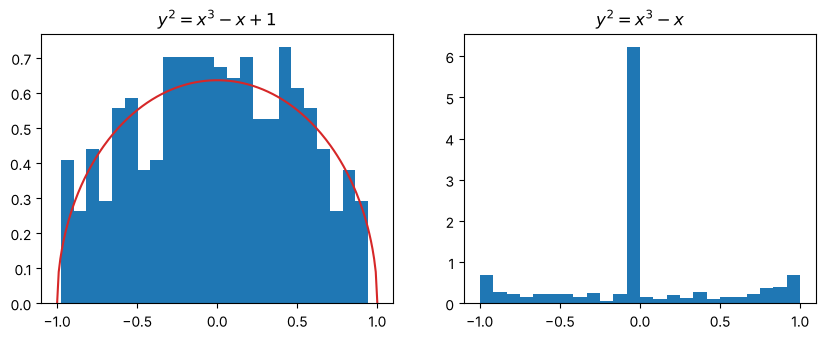

In [5]:
def primes(n):
    s = bytearray([1]) * n; s[:2] = b'\x00\x00'
    for i in range(2, int(n**0.5) + 1):
        if s[i]: s[i*i::i] = bytearray(len(s[i*i::i]))
    return [i for i in range(n) if s[i]]
def legendre(c, p):
    c %= p
    if c == 0: return 0
    return 1 if pow(c, (p - 1) // 2, p) == 1 else -1
def a_p(p, a, b): return -sum(legendre(x**3 + a * x + b, p) for x in range(p))
ps = [p for p in primes(3000) if p > 3]
A1 = [a_p(p, -1, 1) for p in ps if (4 * (-1)**3 + 27) % p]
A2 = [a_p(p, -1, 0) for p in ps]
print('Hasse holds:', all(abs(a_p(p, -1, 1)) <= 2 * math.sqrt(p) for p in ps[:200]))
print('y^2=x^3-x, p = 3 mod 4: a_p always 0?', all(a == 0 for a, p in zip(A2, ps) if p % 4 == 3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist([a / (2 * math.sqrt(p)) for a, p in zip(A1, [p for p in ps if (4 * (-1)**3 + 27) % p])], bins=24, density=True)
t = np.linspace(-1, 1, 200); ax[0].plot(t, 2 / math.pi * np.sqrt(1 - t**2), 'C3'); ax[0].set_title('$y^2=x^3-x+1$')
ax[1].hist([a / (2 * math.sqrt(p)) for a, p in zip(A2, ps)], bins=24, density=True); ax[1].set_title('$y^2=x^3-x$')
plt.show()

For $y^2=x^3-x+1$ the normalised $a_p$ follow the red semicircle: this is the Sato–Tate law, conjectured in the 1960s and proved in 2008–2011 by Clozel, Harris, Shepherd-Barron and Taylor and their coauthors (a remark-level fact, far beyond this book). For $y^2=x^3-x$, half of the primes give $a_p=0$ (Proposition 8.9): this curve has *complex multiplication* by $i$, and the semicircle is replaced by a spike plus a different curve.

### P8.5
**How to find it.** Write $n=im+j$ with $m=\lceil\sqrt{N}\rceil$, $0\le j<m$. Store the baby steps $jP$ in a dictionary, then walk $Q-imP$ until you land in it.

In [6]:
p, a, b = 10007, 2, 3
add = adder(p, a); neg = lambda P: None if P is None else (P[0], (-P[1]) % p)
N = p + 1 - a_p(p, a, b)
x0 = next(x for x in range(1, p) if legendre(x**3 + a * x + b, p) == 1)
y0 = next(y for y in range(p) if (y * y - x0**3 - a * x0 - b) % p == 0)
P = (x0, y0); secret = random.randrange(1, N); Q = mult(secret, P, add)
m = math.isqrt(N) + 1
baby = {}; R = None
for j in range(m):
    baby.setdefault(R, j); R = add(R, P)
step = neg(mult(m, P, add)); R = Q
for i in range(m + 1):
    if R in baby:
        n = i * m + baby[R]; break
    R = add(R, step)
print('#E =', N, ' steps ~', 2 * m, ' found n =', n, ' nP == Q:', mult(n, P, add) == Q)

#E = 9846  steps ~ 200  found n = 3715  nP == Q: True


About $2\sqrt N$ group operations instead of $N$. For a curve with $\#E$ a large prime, of about $2^{256}$, the best known algorithms still need about $\sqrt{\#E}\approx2^{128}$ operations: unlike the multiplicative group $\mathbb F_p^\times$, the points of an elliptic curve have no known extra structure (such as factorisation into small primes) that a cleverer algorithm could exploit. That is the bet of elliptic curve cryptography.